# Spike trains in mouse motor cortex during a delayed-response task

**Dataset:** [DANDI:000006](https://dandiarchive.org/dandiset/000006/0.220126.1855), version `0.220126.1855` (DOI [10.48324/dandi.000006/0.220126.1855](https://doi.org/10.48324/dandi.000006/0.220126.1855)).
*Mouse anterior lateral motor cortex (ALM) in delay response task.* Economo & Svoboda, Janelia Research Campus; associated paper: Economo et al., *Nature* 2018 ([doi:10.1038/s41586-018-0642-9](https://doi.org/10.1038/s41586-018-0642-9)).

**The task.** A head-fixed mouse feels a pole during a **sample** epoch, waits through a **delay**, and after an auditory **go cue** licks left or right to report where the pole was. The correct direction is known on every trial, so each trial has a "planned movement" label before the movement happens.

**What this notebook does**
1. Finds and downloads NWB files from the DANDI Archive with the `dandi` Python client.
2. Reads trials, lick events and sorted spike times with `pynwb`.
3. Checks that the behavioral timestamps line up with the licks they describe.
4. Plots a spike raster and a peri-stimulus time histogram (PSTH) aligned to the go cue.
5. Compares firing across task epochs and between **lick-left vs lick-right** trials, for one session and then for all 53 sessions.

The whole dandiset is about 140 MB, so everything runs on a laptop in a few minutes.

In [1]:
from pathlib import Path
import urllib.request
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pynwb import NWBHDF5IO

warnings.filterwarnings("ignore", message=".*cached namespace.*")  # harmless pynwb notice for older files

DANDISET_ID = "000006"
VERSION = "0.220126.1855"          # pin the published version so results are reproducible
DATA_DIR = Path("data") / DANDISET_ID
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Colors: one per movement direction, used consistently in every figure
LEFT, RIGHT, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titleweight": "bold", "legend.frameon": False,
})

## 1. Find the files on DANDI

`DandiAPIClient` lists every asset (file) in a pinned dandiset version, with its size and a direct S3 URL.
If the DANDI API cannot be reached (for example on a locked-down network), the code falls back to the asset manifest that DANDI publishes for the same version in its public S3 bucket, which lists the same files.

In [2]:
def list_assets(dandiset_id=DANDISET_ID, version=VERSION):
    # Return [(path, size_bytes, s3_url), ...] for every file in the dandiset version.
    try:
        urllib.request.urlopen("https://api.dandiarchive.org/api/info/", timeout=10)  # fail fast if unreachable
        from dandi.dandiapi import DandiAPIClient
        with DandiAPIClient() as client:
            ds = client.get_dandiset(dandiset_id, version)
            return sorted((a.path, a.size, a.get_content_url(regex="s3")) for a in ds.get_assets())
    except Exception as err:
        print(f"DANDI API unavailable ({type(err).__name__}); using the S3 manifest instead.")
        import yaml  # installed with dandi
        url = f"https://dandiarchive.s3.amazonaws.com/dandisets/{dandiset_id}/{version}/assets.yaml"
        with urllib.request.urlopen(url, timeout=60) as r:
            meta = yaml.safe_load(r)
        return sorted((m["path"], m["contentSize"],
                       next(u for u in m["contentUrl"] if "s3" in u)) for m in meta)

assets = list_assets()
print(f"{len(assets)} NWB files, {sum(a[1] for a in assets) / 1e6:.0f} MB in total")
for path, size, _ in assets[:5]:
    print(f"  {path:50s} {size / 1e6:6.1f} MB")

DANDI API unavailable (URLError); using the S3 manifest instead.


53 NWB files, 140 MB in total
  sub-anm369962/sub-anm369962_ses-20170309.nwb          0.8 MB
  sub-anm369962/sub-anm369962_ses-20170310.nwb          6.6 MB
  sub-anm369962/sub-anm369962_ses-20170313.nwb         11.5 MB
  sub-anm369962/sub-anm369962_ses-20170314.nwb          7.5 MB
  sub-anm369962/sub-anm369962_ses-20170316.nwb          0.6 MB


In [3]:
def fetch(path, url):
    # Download one asset to DATA_DIR (skipped if already on disk).
    local = DATA_DIR / Path(path).name
    if not local.exists():
        urllib.request.urlretrieve(url, local)
    return local

SESSION = "sub-anm369962/sub-anm369962_ses-20170313.nwb"   # 71 sorted units, 354 trials
nwb_path = fetch(*next((p, u) for p, _, u in assets if p == SESSION))
print(nwb_path, f"{nwb_path.stat().st_size / 1e6:.1f} MB")

data/000006/sub-anm369962_ses-20170313.nwb 11.5 MB


## 2. Open the NWB file and look at what is inside

NWB (Neurodata Without Borders) is an HDF5-based standard. The parts used here are:

| NWB object | Contents |
|---|---|
| `nwb.trials` | one row per trial: trial type (`lick left` / `lick right`), outcome, and epoch onset times |
| `nwb.units` | one row per sorted neuron: `spike_times`, depth, quality, cell type |
| `nwb.acquisition["lick_times"]` | timestamps of every left and right lick |

In [4]:
io = NWBHDF5IO(str(nwb_path), "r", load_namespaces=True)
nwb = io.read()
print(nwb.experiment_description, "\n")
print("Subject:", nwb.subject.subject_id, "| species:", nwb.subject.species, "| session start:", nwb.session_start_time.date())

for col in nwb.trials.colnames:
    print(f"  trials.{col:15s} {nwb.trials[col].description}")

trials = nwb.trials.to_dataframe()
trials.head()

Extracellular electrophysiology recordings performed on mouse anterior lateral motor cortex (ALM) in delay response task. Neural activity from two neuron populations, pyramidal track upper and lower, were characterized, in relation to movement execution. 

Subject: anm369962 | species: Mus musculus | session start: 2017-03-13
  trials.start_time      Start time of epoch, in seconds
  trials.stop_time       Stop time of epoch, in seconds
  trials.type            
  trials.response        
  trials.stim_present    is this a stim or no-stim trial
  trials.is_good         good/bad status of trial (bad trials are not analyzed)
  trials.cue_start_time  onset of response period
  trials.pole_in_time    onset of sample period
  trials.pole_out_time   onset of the delay period


,start_time,stop_time,type,response,stim_present,is_good,cue_start_time,pole_in_time,pole_out_time
id,,,,,,,,,
1,343.971,NaN,lick right,correct,0,1,6.47531,3.97482,4.97498
2,350.371,NaN,lick right,early lick,0,1,7.97663,4.68998,5.69014
3,356.771,NaN,lick right,early lick,0,1,6.50081,3.90881,4.90898
4,363.171,NaN,lick right,correct,0,1,7.24664,4.74615,5.74631
5,369.571,NaN,lick left,correct,0,1,7.09414,4.59365,5.59381


In [5]:
print(trials["type"].value_counts().to_string(), "\n")
print(trials["response"].value_counts().to_string(), "\n")
print("photostimulation trials:", int(trials["stim_present"].sum()), "| trials flagged bad:", int((trials["is_good"] == 0).sum()))

type
lick left     197
lick right    157 

response
correct       270
incorrect      66
early lick     18 

photostimulation trials: 0 | trials flagged bad: 11


### Time conventions (read the docs, then verify)

`start_time` is in seconds from the start of the session, but `pole_in_time`, `pole_out_time` and `cue_start_time` are small numbers (about 4 to 8 s). They are offsets from the trial's `start_time`, so the go cue of trial *i* in session time is `start_time[i] + cue_start_time[i]`.

That reading of the format is a hypothesis, so it gets tested against independent data: if it is right, licking should start abruptly just after the go cue, and on correct trials the first lick should usually be on the side named by the trial type.

In [6]:
lick_ts = nwb.acquisition["lick_times"].time_series
lick_left = lick_ts["lick_left_times"].timestamps[:]
lick_right = lick_ts["lick_right_times"].timestamps[:]

trials["cue"] = trials["start_time"] + trials["cue_start_time"]        # go cue, session time
trials["sample_on"] = trials["start_time"] + trials["pole_in_time"]    # pole touches whiskers
trials["delay_on"] = trials["start_time"] + trials["pole_out_time"]    # pole withdrawn

# Analysis set: correct, good, unstimulated trials
good = trials[(trials.response == "correct") & (trials.is_good == 1) & (trials.stim_present == 0)].copy()

def first_lick(cue, window=1.5):
    l = lick_left[(lick_left > cue) & (lick_left < cue + window)]
    r = lick_right[(lick_right > cue) & (lick_right < cue + window)]
    if len(l) == 0 and len(r) == 0:
        return None, np.nan
    tl, tr = (l.min() if len(l) else np.inf), (r.min() if len(r) else np.inf)
    return ("lick left" if tl < tr else "lick right"), min(tl, tr) - cue

res = [first_lick(c) for c in good.cue]
good["first_side"] = [s for s, _ in res]
good["lick_latency"] = [t for _, t in res]
agree = (good.first_side == good.type).mean()
print(f"Correct trials analysed: {len(good)}")
print(f"Median first-lick latency after go cue: {1000 * good.lick_latency.median():.0f} ms")
print(f"First lick on the side named by trial type: {100 * agree:.0f}% of correct trials")
print(f"Sample epoch {np.median(good.delay_on - good.sample_on):.2f} s, delay epoch {np.median(good.cue - good.delay_on):.2f} s (medians)")

Correct trials analysed: 261
Median first-lick latency after go cue: 107 ms
First lick on the side named by trial type: 85% of correct trials
Sample epoch 1.00 s, delay epoch 1.50 s (medians)


Licking starts about a tenth of a second after the computed go cue, which supports the time convention. The first-lick agreement is high but not 100%: on some trials labelled correct the mouse touches the other spout first. The dataset does not document how the outcome was scored, so these trials are kept as labelled rather than re-scored here.

## 3. Behavior aligned to the go cue

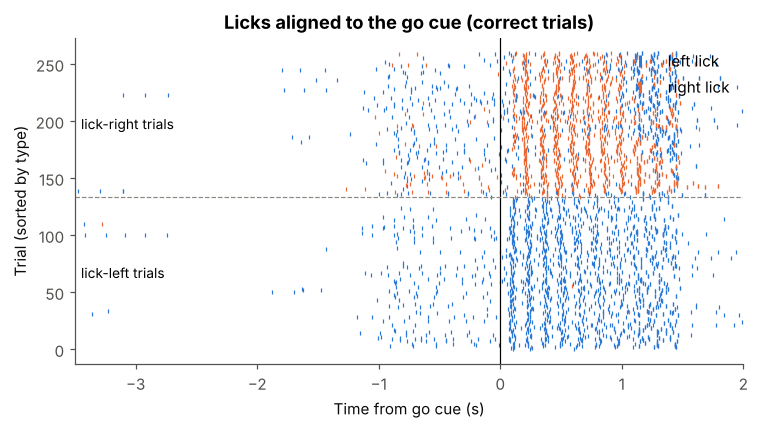

In [7]:
def align(times, events, pre, post):
    # Spike/lick times relative to each event, as a list of arrays (one per trial).
    times = np.asarray(times)
    lo = np.searchsorted(times, events - pre)
    hi = np.searchsorted(times, events + post)
    return [times[a:b] - e for a, b, e in zip(lo, hi, events)]

PRE, POST = 3.5, 2.0   # seconds around the go cue: covers sample, delay and response
order = good.sort_values(["type", "cue"]).reset_index(drop=True)
is_left = (order.type == "lick left").values

fig, ax = plt.subplots(figsize=(7, 4))
for side_times, color, label in [(lick_left, LEFT, "left lick"), (lick_right, RIGHT, "right lick")]:
    rel = align(side_times, order.cue.values, PRE, POST)
    for i, r in enumerate(rel):
        ax.plot(r, np.full(len(r), i), "|", color=color, ms=2.5, mew=0.8)
    ax.plot([], [], "|", color=color, ms=8, mew=2, label=label)
ax.axvline(0, color="k", lw=0.8)
ax.axhline(is_left.sum() - 0.5, color=GREY, lw=0.8, ls="--")
ax.text(-PRE + 0.05, is_left.sum() / 2, "lick-left trials", va="center", fontsize=9)
ax.text(-PRE + 0.05, is_left.sum() + (~is_left).sum() / 2, "lick-right trials", va="center", fontsize=9)
ax.set(xlabel="Time from go cue (s)", ylabel="Trial (sorted by type)", xlim=(-PRE, POST),
       title="Licks aligned to the go cue (correct trials)")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

## 4. Spike trains

`nwb.units` stores each neuron's spike times as one ragged array. Units with very few spikes are dropped so firing-rate estimates are not dominated by noise.

In [8]:
units = nwb.units.to_dataframe()
print(units[["depth", "quality", "cell_type"]].value_counts(["quality", "cell_type"]).to_string(), "\n")

spikes = {uid: np.asarray(st) for uid, st in zip(units.index, units.spike_times)}
session_span = max(s.max() for s in spikes.values()) - min(s.min() for s in spikes.values())
rates = {uid: len(st) / session_span for uid, st in spikes.items()}
keep = [uid for uid, r in rates.items() if r >= 0.5]
print(f"{len(spikes)} units over {session_span / 60:.1f} min; {len(keep)} fire at >= 0.5 Hz and are analysed")

quality    cell_type   
single     unidentified    59
[]         unidentified     7
Excellent  PTlower          5 

71 units over 37.8 min; 69 fire at >= 0.5 Hz and are analysed


### Epoch firing rates and selectivity

Each trial is cut into four windows using that trial's own event times:

| Epoch | Window |
|---|---|
| baseline | 1 s before pole in |
| sample | pole in to pole out |
| delay | pole out to go cue |
| response | go cue to 1 s after |

A unit is **direction-selective** in an epoch if its rate differs between lick-left and lick-right trials (two-sided Mann-Whitney U test, p < 0.01). A unit is **delay-modulated** if its delay rate differs from its own baseline on the same trials (Wilcoxon signed-rank, p < 0.01). With about 70 units the 1% threshold expects under one false positive per test.

In [9]:
EPOCHS = {
    "baseline": lambda t: (t.sample_on - 1.0, t.sample_on),
    "sample":   lambda t: (t.sample_on, t.delay_on),
    "delay":    lambda t: (t.delay_on, t.cue),
    "response": lambda t: (t.cue, t.cue + 1.0),
}

def epoch_rates(st, trials_df):
    # Firing rate (Hz) per trial for every epoch -> dict epoch -> array(n_trials)
    out = {}
    for name, win in EPOCHS.items():
        a, b = win(trials_df)
        n = np.searchsorted(st, b.values) - np.searchsorted(st, a.values)
        out[name] = n / (b.values - a.values)
    return out

def unit_stats(st, trials_df, alpha=0.01):
    r = epoch_rates(st, trials_df)
    L = (trials_df.type == "lick left").values
    row = {}
    for ep, v in r.items():
        row[f"{ep}_L"], row[f"{ep}_R"] = v[L].mean(), v[~L].mean()
        if v[L].std() + v[~L].std() > 0:
            row[f"{ep}_p_dir"] = stats.mannwhitneyu(v[L], v[~L]).pvalue
        else:
            row[f"{ep}_p_dir"] = 1.0
    d = r["delay"] - r["baseline"]
    row["delay_p_mod"] = stats.wilcoxon(d).pvalue if np.any(d != 0) else 1.0
    row["baseline"], row["delay"] = r["baseline"].mean(), r["delay"].mean()
    return row

import pandas as pd
summary = pd.DataFrame({uid: unit_stats(spikes[uid], good) for uid in keep}).T
summary["delay_sel"] = summary.delay_p_dir < 0.01
summary["delay_mod"] = summary.delay_p_mod < 0.01
for ep in EPOCHS:
    print(f"{ep:9s}: {int((summary[f'{ep}_p_dir'] < 0.01).sum()):2d} / {len(summary)} units direction-selective")
print(f"delay vs baseline: {int(summary.delay_mod.sum())} / {len(summary)} units modulated")

baseline :  0 / 69 units direction-selective
sample   : 35 / 69 units direction-selective
delay    : 46 / 69 units direction-selective
response : 53 / 69 units direction-selective
delay vs baseline: 57 / 69 units modulated


### Raster plot and PSTH for one neuron

The example is the unit with the strongest delay-epoch preference (smallest p-value) among units firing at least 2 Hz. Choosing the strongest unit is fine for illustration but means this unit is not typical; the population figures below show the typical picture.

The PSTH counts spikes in 10 ms bins, averages across trials, and smooths with a Gaussian kernel (σ = 50 ms). The shaded band is ±1 standard error across trials.

Example unit 49: depth 1125 µm, 26.0 Hz overall, delay rate L=34.5 Hz vs R=9.1 Hz, p=3.2e-32


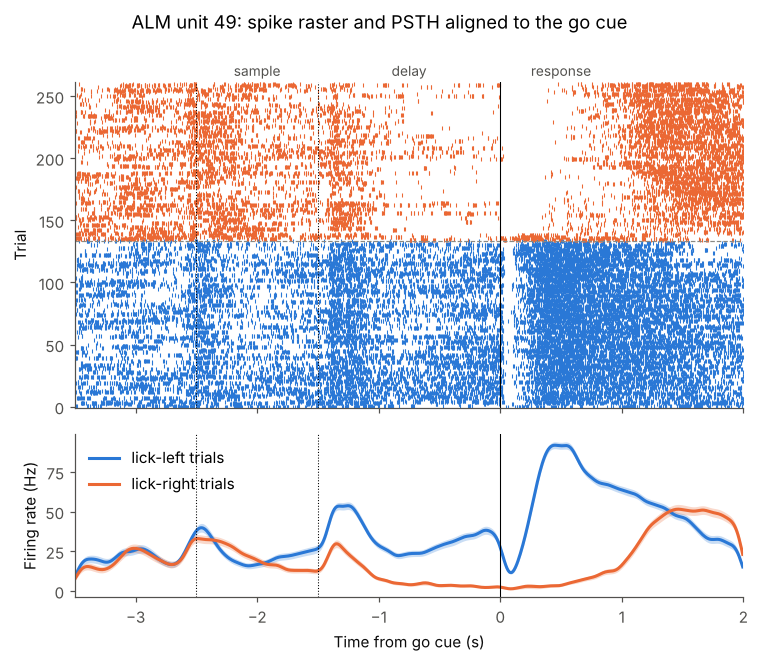

In [10]:
cands = summary[[rates[u] >= 2 for u in summary.index]]
EX = cands.delay_p_dir.astype(float).idxmin()
print(f"Example unit {EX}: depth {units.loc[EX, 'depth']:.0f} µm, {rates[EX]:.1f} Hz overall, "
      f"delay rate L={summary.loc[EX, 'delay_L']:.1f} Hz vs R={summary.loc[EX, 'delay_R']:.1f} Hz, "
      f"p={summary.loc[EX, 'delay_p_dir']:.1e}")

BIN, SIGMA = 0.01, 0.05
edges = np.arange(-PRE, POST + BIN / 2, BIN)
centers = edges[:-1] + BIN / 2
kx = np.arange(-4 * SIGMA, 4 * SIGMA + BIN / 2, BIN)
kernel = np.exp(-kx**2 / (2 * SIGMA**2)); kernel /= kernel.sum()

def psth(aligned):
    counts = np.array([np.histogram(r, edges)[0] for r in aligned]) / BIN    # Hz, trials x bins
    sm = np.array([np.convolve(c, kernel, mode="same") for c in counts])
    return sm.mean(0), sm.std(0, ddof=1) / np.sqrt(len(sm))

def raster_psth(uid, axr, axp, label_epochs=True):
    rel = align(spikes[uid], order.cue.values, PRE, POST)
    for i, r in enumerate(rel):
        axr.plot(r, np.full(len(r), i), "|", color=LEFT if is_left[i] else RIGHT, ms=2.2, mew=0.7)
    axr.axhline(is_left.sum() - 0.5, color=GREY, lw=0.8, ls="--")
    for side, color, name in [(is_left, LEFT, "lick-left trials"), (~is_left, RIGHT, "lick-right trials")]:
        m, se = psth([r for r, s in zip(rel, side) if s])
        axp.fill_between(centers, m - se, m + se, color=color, alpha=0.25, lw=0)
        axp.plot(centers, m, color=color, lw=2, label=name)
    # epoch boundaries: median onset relative to the cue
    s_on, d_on = np.median(order.sample_on - order.cue), np.median(order.delay_on - order.cue)
    for ax in (axr, axp):
        for x in (s_on, d_on, 0):
            ax.axvline(x, color="k", lw=0.7, ls=":" if x else "-")
    if label_epochs:
        for x0, x1, lab in [(s_on, d_on, "sample"), (d_on, 0, "delay"), (0, 1.0, "response")]:
            axr.text((x0 + x1) / 2, 1.01, lab, transform=axr.get_xaxis_transform(), ha="center", va="bottom", fontsize=9, color="#52514e")
    axr.set(ylabel="Trial", xlim=(-PRE, POST), ylim=(-1, len(rel)))
    axr.tick_params(labelbottom=False)
    axp.set(xlabel="Time from go cue (s)", ylabel="Firing rate (Hz)", xlim=(-PRE, POST))

fig, (axr, axp) = plt.subplots(2, 1, figsize=(7, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
raster_psth(EX, axr, axp)
axp.legend(loc="upper left")
fig.suptitle(f"ALM unit {EX}: spike raster and PSTH aligned to the go cue", y=0.995)
plt.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/raster_psth.png", bbox_inches="tight", facecolor="white")
plt.show()

### Population raster for a single trial

A different view of the same data: every analysed unit on one trial, sorted by depth along the probe.

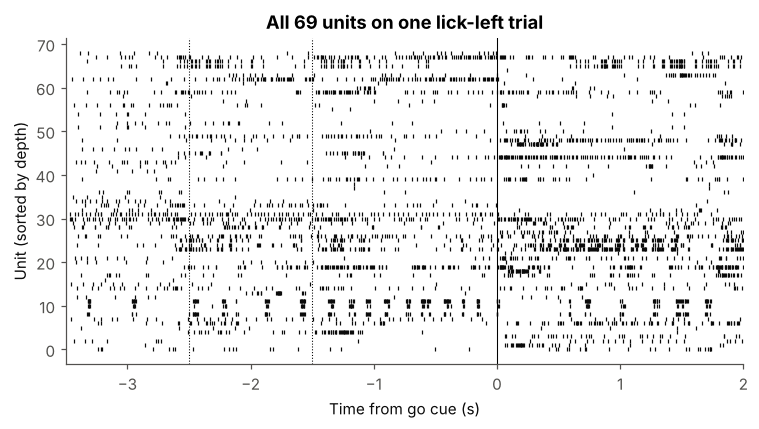

In [11]:
trial = order.iloc[np.where(is_left)[0][len(np.where(is_left)[0]) // 2]]
by_depth = sorted(keep, key=lambda u: units.loc[u, "depth"])
fig, ax = plt.subplots(figsize=(7, 4))
for i, uid in enumerate(by_depth):
    st = spikes[uid]
    r = st[(st > trial.cue - PRE) & (st < trial.cue + POST)] - trial.cue
    ax.plot(r, np.full(len(r), i), "|", color="#0b0b0b", ms=3, mew=0.8)
for x in (trial.sample_on - trial.cue, trial.delay_on - trial.cue, 0):
    ax.axvline(x, color="k", lw=0.7, ls=":" if x else "-")
ax.set(xlabel="Time from go cue (s)", ylabel="Unit (sorted by depth)", xlim=(-PRE, POST),
       title=f"All {len(keep)} units on one lick-left trial")
plt.tight_layout(); plt.show()

## 5. Condition comparison

Two comparisons for every analysed unit in this session:

* **Epoch (within trial):** delay-epoch rate vs baseline rate. Points off the diagonal changed their firing once the animal had information to hold in mind.
* **Direction (between trial types):** delay rate on lick-left vs lick-right trials. Points off the diagonal predict the upcoming movement before it happens.

The third panel summarises direction preference over time across all selective units: for each unit, `(R − L) / (R + L)` on the smoothed PSTHs, sign-flipped so that the unit's preferred direction is positive, then averaged. Flipping by the delay-epoch preference makes the delay period positive by construction, so the informative part is when selectivity first appears and whether it carries into the response epoch.

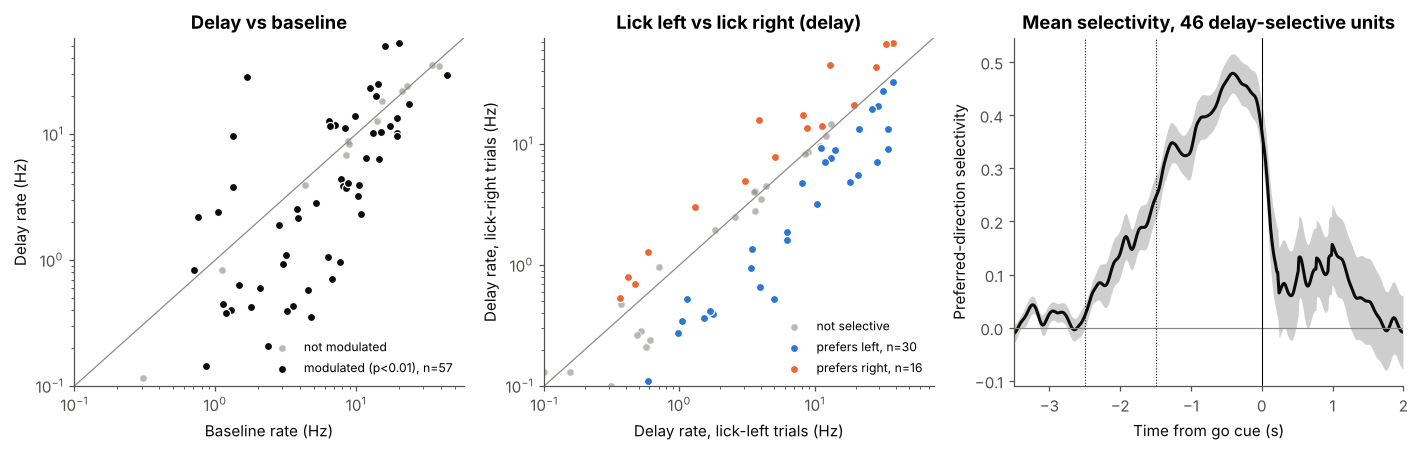

In [12]:
def selectivity_trace(uid, ref_sign):
    rel = align(spikes[uid], order.cue.values, PRE, POST)
    mL, _ = psth([r for r, s in zip(rel, is_left) if s])
    mR, _ = psth([r for r, s in zip(rel, ~is_left) if s])
    return ref_sign * (mR - mL) / (mR + mL + 1e-9)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))

ax = axes[0]
lim = max(summary.baseline.max(), summary.delay.max()) * 1.1
mod = summary.delay_mod.values
ax.plot([0.1, lim], [0.1, lim], color=GREY, lw=0.8)
ax.scatter(summary.baseline[~mod], summary.delay[~mod], s=24, color=GREY, alpha=0.6, label="not modulated", edgecolor="white", lw=0.8)
ax.scatter(summary.baseline[mod], summary.delay[mod], s=28, color="#0b0b0b", label=f"modulated (p<0.01), n={mod.sum()}", edgecolor="white", lw=0.8)
ax.set(xscale="log", yscale="log", xlim=(0.1, lim), ylim=(0.1, lim), xlabel="Baseline rate (Hz)", ylabel="Delay rate (Hz)",
       title="Delay vs baseline")
ax.legend(loc="lower right", fontsize=8)

ax = axes[1]
sel = summary.delay_sel.values
lim = max(summary.delay_L.max(), summary.delay_R.max()) * 1.1
ax.plot([0.1, lim], [0.1, lim], color=GREY, lw=0.8)
ax.scatter(summary.delay_L[~sel], summary.delay_R[~sel], s=24, color=GREY, alpha=0.6, label="not selective", edgecolor="white", lw=0.8)
prefR = sel & (summary.delay_R > summary.delay_L).values
prefL = sel & ~prefR
ax.scatter(summary.delay_L[prefL], summary.delay_R[prefL], s=28, color=LEFT, label=f"prefers left, n={prefL.sum()}", edgecolor="white", lw=0.8)
ax.scatter(summary.delay_L[prefR], summary.delay_R[prefR], s=28, color=RIGHT, label=f"prefers right, n={prefR.sum()}", edgecolor="white", lw=0.8)
ax.set(xscale="log", yscale="log", xlim=(0.1, lim), ylim=(0.1, lim), xlabel="Delay rate, lick-left trials (Hz)",
       ylabel="Delay rate, lick-right trials (Hz)", title="Lick left vs lick right (delay)")
ax.legend(loc="lower right", fontsize=8)

ax = axes[2]
sel_ids = summary.index[sel]
traces = np.array([selectivity_trace(u, np.sign(summary.loc[u, "delay_R"] - summary.loc[u, "delay_L"])) for u in sel_ids])
m, se = traces.mean(0), traces.std(0, ddof=1) / np.sqrt(len(traces))
ax.fill_between(centers, m - se, m + se, color="#0b0b0b", alpha=0.2, lw=0)
ax.plot(centers, m, color="#0b0b0b", lw=2)
ax.axhline(0, color=GREY, lw=0.8)
for x in (np.median(order.sample_on - order.cue), np.median(order.delay_on - order.cue), 0):
    ax.axvline(x, color="k", lw=0.7, ls=":" if x else "-")
ax.set(xlim=(-PRE, POST), xlabel="Time from go cue (s)", ylabel="Preferred-direction selectivity",
       title=f"Mean selectivity, {len(sel_ids)} delay-selective units")
plt.tight_layout()
fig.savefig("figures/condition_comparison.png", bbox_inches="tight", facecolor="white")
plt.show()

## 6. Scale up: all 53 sessions

The same per-unit statistics, run on every file in the dandiset. This downloads the remaining ~130 MB the first time.

In [13]:
rows, total_seconds, total_trials = [], 0.0, 0
for path, size, url in assets:
    with NWBHDF5IO(str(fetch(path, url)), "r", load_namespaces=True) as f:
        n = f.read()
        tr = n.trials.to_dataframe()
        tr["cue"] = tr.start_time + tr.cue_start_time
        tr["sample_on"] = tr.start_time + tr.pole_in_time
        tr["delay_on"] = tr.start_time + tr.pole_out_time
        g = tr[(tr.response == "correct") & (tr.is_good == 1) & (tr.stim_present == 0)]
        u = n.units.to_dataframe()
        sts = [np.asarray(s) for s in u.spike_times]
        span = max(s.max() for s in sts) - min(s.min() for s in sts)
        total_seconds += span
        total_trials += len(tr)
        nL = (g.type == "lick left").sum()
        for uid, st, ct in zip(u.index, sts, u.cell_type):
            if len(st) / span < 0.5 or nL < 10 or len(g) - nL < 10:
                continue
            r = unit_stats(st, g)
            r.update(session=Path(path).stem, unit=uid, cell_type=ct)
            rows.append(r)

allu = pd.DataFrame(rows)
print(f"Recording time: {total_seconds / 3600:.1f} h across {len(assets)} sessions, {total_trials} trials")
print(f"Units analysed (>= 0.5 Hz): {len(allu)} from {allu.session.nunique()} sessions")
frac = pd.DataFrame({ep: [(allu[f"{ep}_p_dir"] < 0.01).mean()] for ep in EPOCHS}, index=["fraction direction-selective"]).T
print(frac.round(3).to_string())

Recording time: 26.8 h across 53 sessions, 15149 trials
Units analysed (>= 0.5 Hz): 1073 from 53 sessions
          fraction direction-selective
baseline                         0.035
sample                           0.536
delay                            0.643
response                         0.741


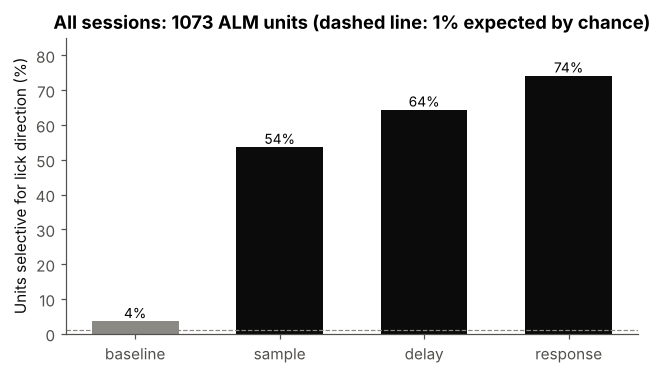

In [14]:
fig, ax = plt.subplots(figsize=(6, 3.5))
vals = frac.iloc[:, 0].values * 100
bars = ax.bar(list(EPOCHS), vals, color=[GREY, "#0b0b0b", "#0b0b0b", "#0b0b0b"], width=0.6)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
ax.axhline(1, color=GREY, lw=0.8, ls="--")
ax.set(ylabel="Units selective for lick direction (%)", ylim=(0, 85),
       title=f"All sessions: {len(allu)} ALM units (dashed line: 1% expected by chance)")
plt.tight_layout()
fig.savefig("figures/population_selectivity.png", bbox_inches="tight", facecolor="white")
plt.show()

## 7. Interpretation

In this session, 46 of 69 analysed units fired at different rates during the delay depending on which way the mouse was about to lick, at a time when it had felt the pole but had not yet been allowed to move; across all 53 sessions the figure is 64% of 1,073 units, compared with 4% in the pre-sample baseline, which serves as a control because the trial type is not yet knowable then. The example unit shows the effect on single trials: about 35 Hz in the delay before left licks against 9 Hz before right licks, so the upcoming choice can be read from its spikes roughly 1.5 s before the go cue. Selectivity emerges during the sample epoch and keeps climbing through the delay, peaking just before the go cue, which is the pattern expected of preparatory (motor-planning) activity rather than a purely sensory or purely motor signal. The baseline rate of 4% is above the 1% expected by chance, which suggests a small contribution from slow drift or trial-history effects that a stricter analysis would control for.

**Limitations.** Selectivity tests are per unit and uncorrected across units and epochs; the 1% threshold keeps the expected false-positive count low but not zero. Rates are averaged over fixed windows, so fast dynamics inside an epoch are only visible in the PSTHs. Only correct trials are used, so this analysis cannot separate "planned direction" from "remembered stimulus location"; error trials, where the two disagree, would be the next step. The cell-type labels in the files mark only a few identified pyramidal-tract neurons per session, so no cell-type comparison is attempted.

In [15]:
io.close()